In [1]:
import scanpy as sc
adata = sc.datasets.pbmc3k()
adata

/home/rhyth/ngs/pyenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5.58M/5.58M [00:03<00:00, 1.49MB/s]


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

<class 'scipy.sparse._csr.csr_matrix'>
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
max value: 419.0
genes detected in no cell: 16104
mitochondrial genes: 13
       n_genes_by_counts  total_counts  pct_counts_mt
count        2700.000000   2700.000000    2700.000000
mean          846.994074   2366.900391       2.215132
std           282.104964   1094.262085       1.165438
min           212.000000    548.000000       0.000000
25%           690.000000   1757.750000       1.536238
50%           817.000000   2197.000000       2.029639
75%           953.250000   2763.000000       2.640218
max          3422.000000  15844.000000      22.569027


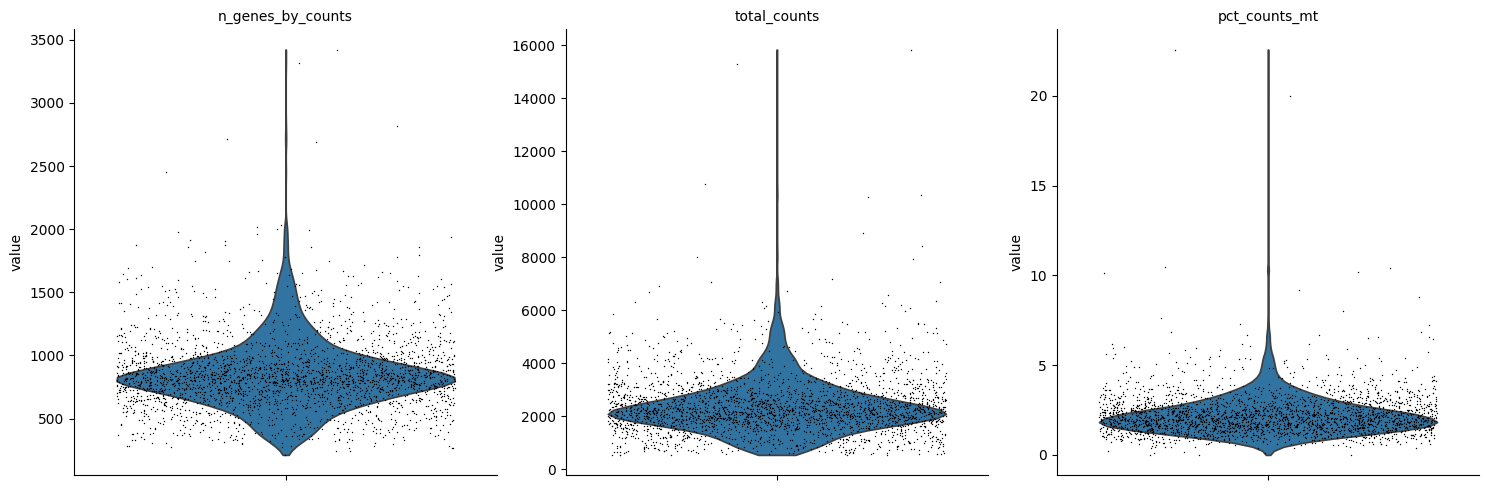

In [2]:
import numpy as np
import matplotlib.pyplot as plt

print(type(adata.X))
print(adata.X[:5, :5].toarray())
print("max value:", adata.X.max())
print("genes detected in no cell:", int((np.asarray(adata.X.sum(axis=0)).ravel() == 0).sum()))

adata.var["mt"] = adata.var_names.str.startswith("MT-")
print("mitochondrial genes:", int(adata.var["mt"].sum()))

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
print(adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe())

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True)

      n_genes_by_counts  total_counts  pct_counts_mt
0.50             817.00       2197.00       2.029639
0.90            1180.10       3551.20       3.403521
0.95            1368.10       4220.55       4.014658
0.99            1749.01       5928.62       5.876420
n_genes > 2000 : 8
n_genes > 2500 : 5
n_genes > 3000 : 2
pct_mt > 4 : 137
pct_mt > 5 : 57
pct_mt > 7 : 12
pct_mt > 10 : 6
n_genes < 200: 0
genes in fewer than 1 cells: 16104
genes in fewer than 3 cells: 19024
genes in fewer than 10 cells: 21599


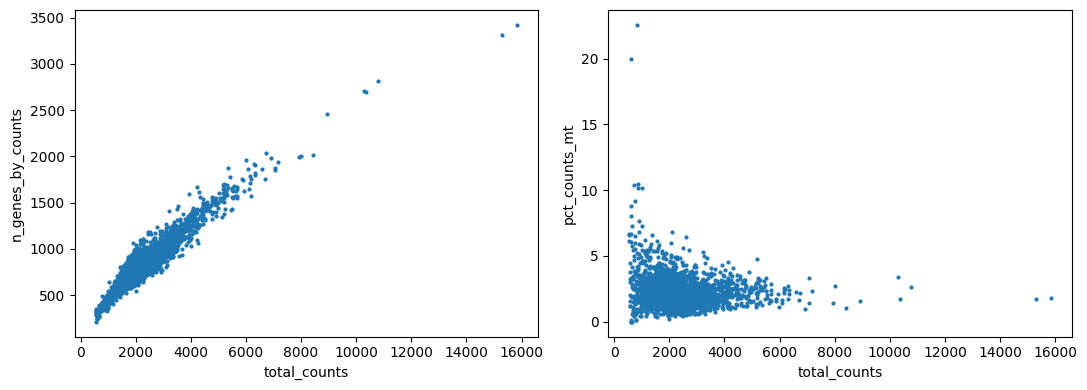

In [3]:
q = adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].quantile([0.5, 0.9, 0.95, 0.99])
print(q)

for t in [2000, 2500, 3000]:
    print("n_genes >", t, ":", int((adata.obs["n_genes_by_counts"] > t).sum()))
for t in [4, 5, 7, 10]:
    print("pct_mt >", t, ":", int((adata.obs["pct_counts_mt"] > t).sum()))
print("n_genes < 200:", int((adata.obs["n_genes_by_counts"] < 200).sum()))

cells_per_gene = np.asarray((adata.X > 0).sum(axis=0)).ravel()
for t in [1, 3, 10]:
    print("genes in fewer than", t, "cells:", int((cells_per_gene < t).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"], s=4)
ax[0].set_xlabel("total_counts"); ax[0].set_ylabel("n_genes_by_counts")
ax[1].scatter(adata.obs["total_counts"], adata.obs["pct_counts_mt"], s=4)
ax[1].set_xlabel("total_counts"); ax[1].set_ylabel("pct_counts_mt")
plt.tight_layout(); plt.show()

cells: 2700 -> 2638 | genes: 32738 -> 13656
max after normalising: 7.4695992
row 0 sums back to: 9999.966
highly variable genes: 2000


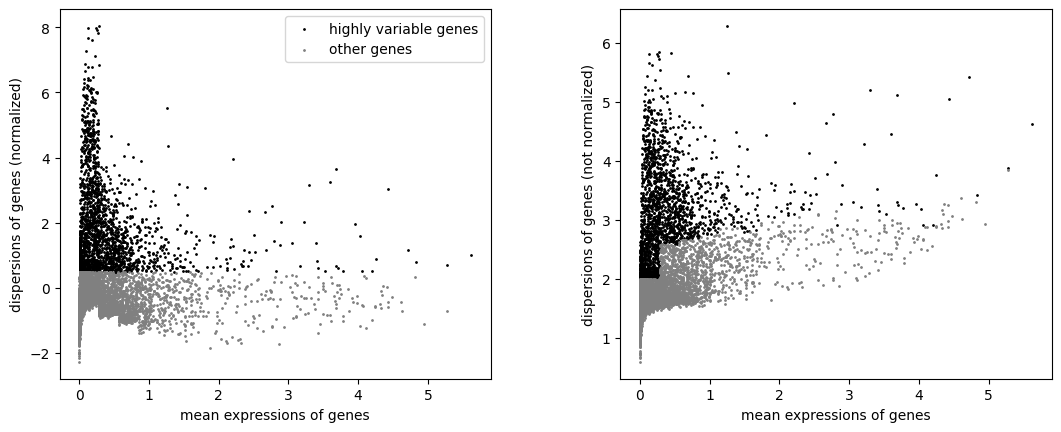

In [4]:
n0, g0 = adata.n_obs, adata.n_vars
sc.pp.filter_cells(adata, min_genes=200)
adata = adata[adata.obs["n_genes_by_counts"] < 2500, :]
adata = adata[adata.obs["pct_counts_mt"] < 5, :].copy()
sc.pp.filter_genes(adata, min_cells=3)
print("cells:", n0, "->", adata.n_obs, "| genes:", g0, "->", adata.n_vars)

adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("max after normalising:", adata.X.max())
print("row 0 sums back to:", adata.X[0].expm1().sum())

sc.pp.highly_variable_genes(adata, n_top_genes=2000)
print("highly variable genes:", int(adata.var["highly_variable"].sum()))
sc.pl.highly_variable_genes(adata)

In [5]:
%pip install --default-timeout=300 igraph

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 7.2 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


/usr/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


PCA shape: (2638, 50)
variance explained, first 10 PCs: [0.025 0.013 0.01  0.009 0.005 0.003 0.002 0.002 0.002 0.002]
cumulative, first 10 / 20 / 30 PCs: 0.073 0.091 0.108


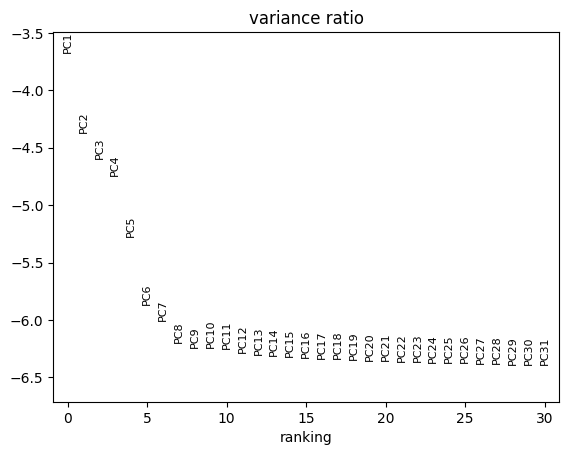

In [6]:
adata.raw = adata  # keep normalised, log-transformed values for all genes
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack", mask_var="highly_variable")
print("PCA shape:", adata.obsm["X_pca"].shape)
vr = adata.uns["pca"]["variance_ratio"]
print("variance explained, first 10 PCs:", vr[:10].round(3))
print("cumulative, first 10 / 20 / 30 PCs:", vr[:10].sum().round(3), vr[:20].sum().round(3), vr[:30].sum().round(3))
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)

igraph 1.0.0
leiden
0     176
1     167
2     344
3     320
4     355
5     206
6      15
7     155
8     283
9      39
10    172
11    260
12    146
Name: count, dtype: int64


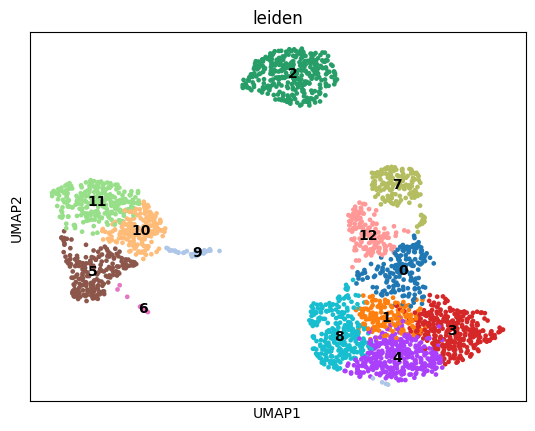

In [7]:
import igraph
print("igraph", igraph.__version__)

sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10)
sc.tl.umap(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.9, random_state=0, flavor="igraph", n_iterations=2, directed=False)
print(adata.obs["leiden"].value_counts().sort_index())
sc.pl.umap(adata, color="leiden", legend_loc="on data")

         0         1         2         3         4
0     CCL5      GZMK      IL32      NKG7       B2M
1    RPS12      RPS3      IL32    RPL27A     RPS14
2     CD74     CD79A   HLA-DRA     CD79B  HLA-DPB1
3      LTB      IL32      CD3D      LDHB      CD3E
4     LDHB     RPS27     RPS12      RPS6     RPS25
5     LST1     COTL1    FCER1G      AIF1    IFITM3
6     PPBP      NRGN      GPX1     RGS10     CALM3
7     NKG7      GNLY      GZMB      CTSW      PRF1
8    RPL32     RPS27    MALAT1     RPS12     RPL13
9   FCER1A  HLA-DQA1  HLA-DPB1  HLA-DPA1  HLA-DRB1
10     LYZ      FCN1    S100A9    LGALS2      CST3
11  S100A8    S100A9       LYZ       FTL    TYROBP
12    NKG7      CCL5      CST7       B2M      GZMH
15 of 15 markers present


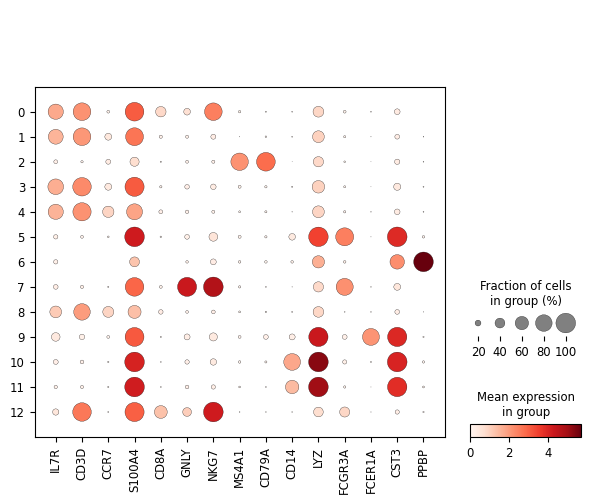

In [8]:
import pandas as pd

sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon", use_raw=True)
names = adata.uns["rank_genes_groups"]["names"]
print(pd.DataFrame(names).head(5).T)

markers = ["IL7R", "CD3D", "CCR7", "S100A4", "CD8A", "GNLY", "NKG7",
           "MS4A1", "CD79A", "CD14", "LYZ", "FCGR3A", "FCER1A", "CST3", "PPBP"]
markers = [m for m in markers if m in adata.raw.var_names]
print(len(markers), "of 15 markers present")
sc.pl.dotplot(adata, markers, groupby="leiden", use_raw=True)

12 of 12 present


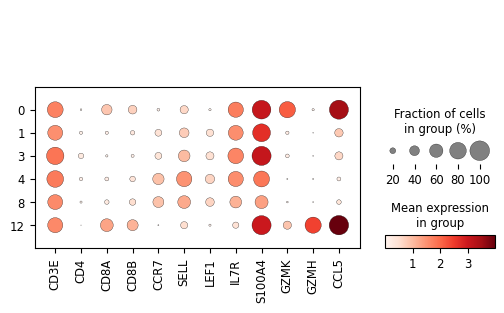


cluster 10 vs 11: higher in 10
      names  logfoldchanges     pvals_adj
0      CD74        1.357317  7.357872e-19
1  HLA-DRB1        1.774741  7.357872e-19
2   HLA-DRA        1.248184  6.455587e-13
3  HLA-DPA1        1.662313  7.188233e-12
4  HLA-DRB5        1.745549  8.994191e-12
5     HLA-C        0.915473  2.763740e-11
higher in 11
        names  logfoldchanges     pvals_adj
13650  S100A6       -0.204969  8.813349e-03
13651   EEF1D       -0.287939  2.301297e-03
13652  S100A9       -0.544972  1.949364e-03
13653  TMSB4X       -0.336378  8.911878e-08
13654  S100A8       -1.080742  2.763740e-11
13655     FTL       -0.401552  6.455587e-13

cluster 12 vs 0: higher in 12
    names  logfoldchanges     pvals_adj
0    NKG7        2.611714  4.927472e-37
1    GZMH        6.260660  3.788863e-27
2    CST7        2.167957  7.523902e-18
3    GZMB        5.492215  5.530301e-13
4  FGFBP2        4.426707  1.919054e-11
5   HLA-C        0.600226  6.453488e-11
higher in 0
       names  logfoldchanges  

In [9]:
tmark = ["CD3E", "CD4", "CD8A", "CD8B", "CCR7", "SELL", "LEF1", "IL7R", "S100A4", "GZMK", "GZMH", "CCL5"]
tmark = [g for g in tmark if g in adata.raw.var_names]
print(len(tmark), "of 12 present")
tsub = adata[adata.obs["leiden"].isin(["0", "12", "1", "3", "4", "8"])].copy()
tsub.obs["leiden"] = tsub.obs["leiden"].cat.remove_unused_categories()
sc.pl.dotplot(tsub, tmark, groupby="leiden", use_raw=True)

for g, ref in [("10", "11"), ("12", "0")]:
    sc.tl.rank_genes_groups(adata, "leiden", groups=[g], reference=ref, method="wilcoxon",
                            use_raw=True, key_added=f"rg_{g}_vs_{ref}")
    d = sc.get.rank_genes_groups_df(adata, group=g, key=f"rg_{g}_vs_{ref}")
    print(f"\ncluster {g} vs {ref}: higher in {g}")
    print(d.head(6)[["names", "logfoldchanges", "pvals_adj"]])
    print(f"higher in {ref}")
    print(d.tail(6)[["names", "logfoldchanges", "pvals_adj"]])

cell_type
Naive-like T         638
Memory-like T        487
CD14+ monocytes      432
B                    344
FCGR3A+ monocytes    206
GZMK+ cytotoxic T    176
NK                   155
GZMH+ cytotoxic T    146
Dendritic             39
Platelets             15
Name: count, dtype: int64
unlabeled cells: 0


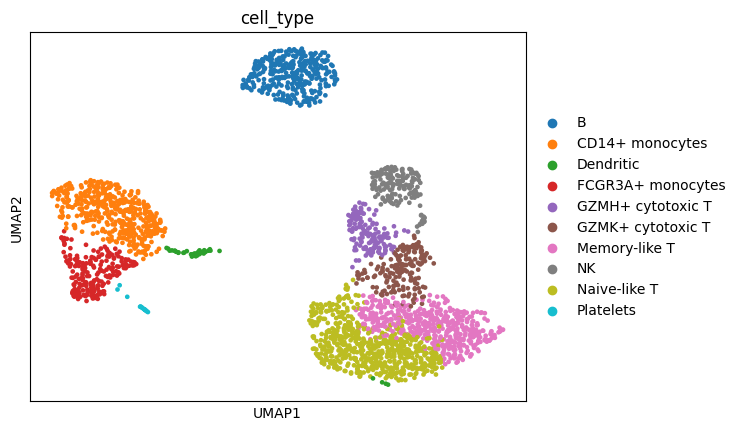

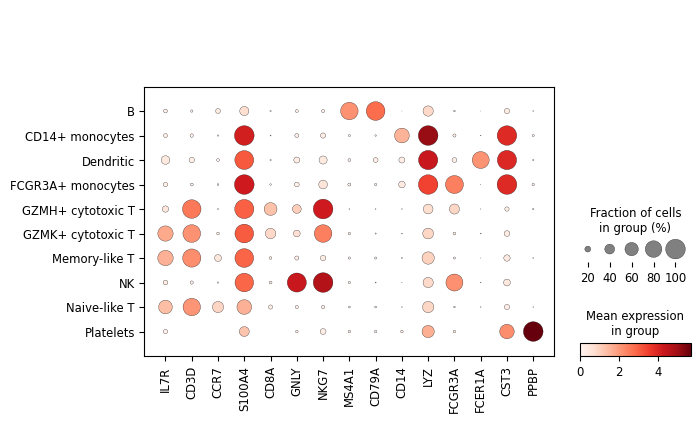

clusters with 20 PCs: 9
ARI, 10 vs 20 PCs: 0.578
['dotplot__markers.png', 'umap_cell_types.png'] ['top_markers_per_cluster.csv', 'cell_annotations.csv']


/tmp/ipykernel_5975/3684718289.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mk.groupby("group").head(20).to_csv("results/top_markers_per_cluster.csv", index=False)


In [10]:
import os
from sklearn.metrics import adjusted_rand_score
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
sc.settings.figdir = "figures"

labels = {"0": "GZMK+ cytotoxic T", "1": "Memory-like T", "2": "B", "3": "Memory-like T",
          "4": "Naive-like T", "5": "FCGR3A+ monocytes", "6": "Platelets", "7": "NK",
          "8": "Naive-like T", "9": "Dendritic", "10": "CD14+ monocytes",
          "11": "CD14+ monocytes", "12": "GZMH+ cytotoxic T"}
adata.obs["cell_type"] = adata.obs["leiden"].map(labels).astype("category")
print(adata.obs["cell_type"].value_counts())
print("unlabeled cells:", int(adata.obs["cell_type"].isna().sum()))

sc.pl.umap(adata, color="cell_type", legend_loc="right margin", save="_cell_types.png")
sc.pl.dotplot(adata, markers, groupby="cell_type", use_raw=True, save="_markers.png")

sc.pp.neighbors(adata, n_neighbors=10, n_pcs=20, key_added="nn20")
sc.tl.leiden(adata, resolution=0.9, random_state=0, flavor="igraph", n_iterations=2,
             directed=False, neighbors_key="nn20", key_added="leiden_20pc")
print("clusters with 20 PCs:", adata.obs["leiden_20pc"].nunique())
print("ARI, 10 vs 20 PCs:", round(adjusted_rand_score(adata.obs["leiden"], adata.obs["leiden_20pc"]), 3))

cols = ["leiden", "cell_type", "n_genes_by_counts", "total_counts", "pct_counts_mt"]
adata.obs[cols].to_csv("results/cell_annotations.csv")
mk = sc.get.rank_genes_groups_df(adata, group=None)
mk.groupby("group").head(20).to_csv("results/top_markers_per_cluster.csv", index=False)
print(os.listdir("figures"), os.listdir("results"))

In [11]:
ct = pd.crosstab(adata.obs["cell_type"], adata.obs["leiden_20pc"])
print(ct)
print((ct.max(axis=1) / ct.sum(axis=1)).round(2))

leiden_20pc          0    1    2    3   4    5    6    7   8
cell_type                                                   
B                    1    0  343    0   0    0    0    0   0
CD14+ monocytes      0    0    0    5   0    0    0  425   2
Dendritic            0    4    0    0   0    0    0    0  35
FCGR3A+ monocytes    0    0    0  192   0    0    0   14   0
GZMH+ cytotoxic T    1    0    0    0   0    0  145    0   0
GZMK+ cytotoxic T   29    5    0    0   0    0  142    0   0
Memory-like T      399   85    0    0   0    0    3    0   0
NK                   0    0    0    0   0  153    2    0   0
Naive-like T       171  466    0    0   0    0    1    0   0
Platelets            0    0    0    0  15    0    0    0   0
cell_type
B                    1.00
CD14+ monocytes      0.98
Dendritic            0.90
FCGR3A+ monocytes    0.93
GZMH+ cytotoxic T    0.99
GZMK+ cytotoxic T    0.81
Memory-like T        0.82
NK                   0.99
Naive-like T         0.73
Platelets            1.0

In [12]:
ct = pd.crosstab(adata.obs["cell_type"], adata.obs["leiden_20pc"])
print(ct)
print((ct.max(axis=1) / ct.sum(axis=1)).round(2))

leiden_20pc          0    1    2    3   4    5    6    7   8
cell_type                                                   
B                    1    0  343    0   0    0    0    0   0
CD14+ monocytes      0    0    0    5   0    0    0  425   2
Dendritic            0    4    0    0   0    0    0    0  35
FCGR3A+ monocytes    0    0    0  192   0    0    0   14   0
GZMH+ cytotoxic T    1    0    0    0   0    0  145    0   0
GZMK+ cytotoxic T   29    5    0    0   0    0  142    0   0
Memory-like T      399   85    0    0   0    0    3    0   0
NK                   0    0    0    0   0  153    2    0   0
Naive-like T       171  466    0    0   0    0    1    0   0
Platelets            0    0    0    0  15    0    0    0   0
cell_type
B                    1.00
CD14+ monocytes      0.98
Dendritic            0.90
FCGR3A+ monocytes    0.93
GZMH+ cytotoxic T    0.99
GZMK+ cytotoxic T    0.81
Memory-like T        0.82
NK                   0.99
Naive-like T         0.73
Platelets            1.0